## О датасете

Согласно данным **Всемирной организации здравоохранения (ВОЗ)**, инсульт является **второй ведущей причиной смерти в мире** и составляет примерно **11% от общего числа смертей**.

Данный датасет используется для решения задачи **бинарной классификации** — предсказания того, перенесёт ли пациент инсульт.

Модель должна определить вероятность инсульта на основе различных характеристик пациента, включая:

- пол;
- возраст;
- наличие гипертонии;
- наличие сердечных заболеваний;
- средний уровень глюкозы в крови;
- индекс массы тела (ИМТ);
- статус курения;
- тип занятости;
- место проживания;
- семейное положение.

Каждая строка датасета содержит информацию об **одном пациенте**.

### Целевая переменная

**`stroke`** — целевой признак, который показывает, был ли у пациента инсульт:

- `0` — инсульта не было;
- `1` — пациент перенёс инсульт.

## Описание признаков датасета

1. **`id`** — уникальный идентификатор пациента.

2. **`gender`** — пол пациента:
   - `Male` — мужчина
   - `Female` — женщина
   - `Other` — другой

3. **`age`** — возраст пациента.

4. **`hypertension`** — наличие гипертонии:
   - `0` — гипертонии нет
   - `1` — гипертония есть

5. **`heart_disease`** — наличие сердечного заболевания:
   - `0` — сердечного заболевания нет
   - `1` — сердечное заболевание есть

6. **`ever_married`** — был ли пациент когда-либо женат/замужем:
   - `No` — нет
   - `Yes` — да

7. **`work_type`** — тип занятости пациента:
   - `children` — ребёнок
   - `Govt_jov` — государственная служба
   - `Never_worked` — никогда не работал
   - `Private` — частный сектор
   - `Self-employed` — самозанятый

8. **`Residence_type`** — тип места проживания:
   - `Rural` — сельская местность
   - `Urban` — городская местность

9. **`avg_glucose_level`** — средний уровень глюкозы в крови.

10. **`bmi`** — индекс массы тела (ИМТ).

11. **`smoking_status`** — статус курения:
    - `formerly smoked` — курил ранее
    - `never smoked` — никогда не курил
    - `smokes` — курит
    - `Unknown` — информация отсутствует

12. **`stroke`** — целевой признак, показывающий наличие инсульта:
    - `0` — инсульта не было
    - `1` — пациент перенёс инсульт

> **Примечание:** значение `Unknown` в `smoking_status` означает, что информация о статусе курения пациента недоступна.

In [ ]:
# =========================
# Работа с данными
# =========================

import numpy as np
import pandas as pd


# =========================
# Визуализация
# =========================

import matplotlib.pyplot as plt
import seaborn as sns


# =========================
# Предобработка
# =========================

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline


# =========================
# Разделение данных
# =========================

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_score
)


# =========================
# Модели
# =========================

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier
)

from sklearn.svm import SVC

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# =========================
# Метрики
# =========================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay
)


# =========================
# Подбор гиперпараметров
# =========================

import optuna

# =========================
# Дополнительно
# =========================

import warnings
import joblib

: 

In [5]:
warnings.filterwarnings("ignore")

In [6]:
sns.set_theme(
    style="whitegrid",
    palette="deep"
)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

sns.set_palette("Set2")

In [7]:
df = pd.read_csv("../data/healthcare-dataset-stroke-data.csv")
df.head(5)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [8]:
df.tail(1)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [9]:
df.shape

(5110, 12)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


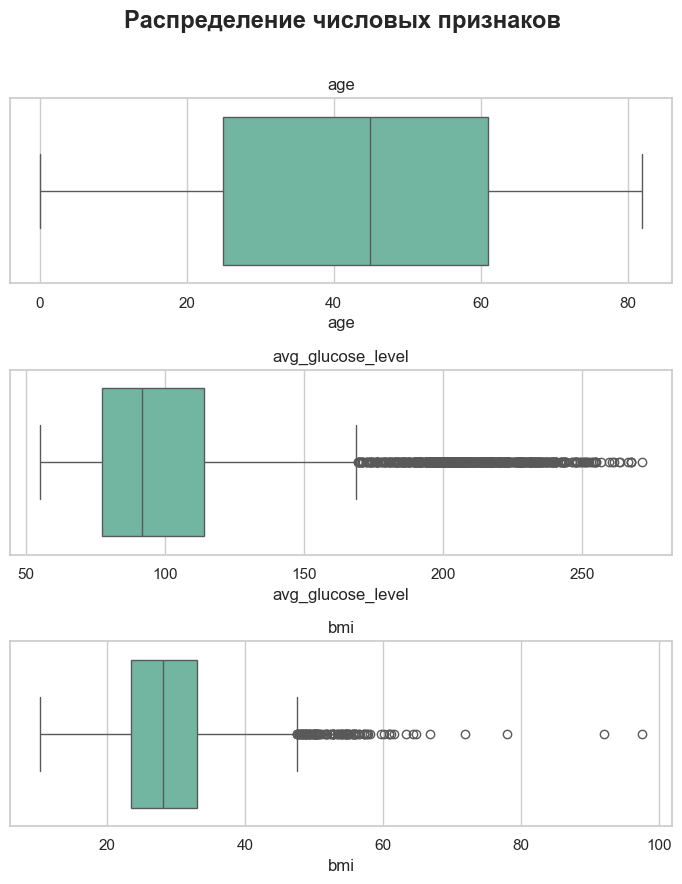

In [11]:
num_cols = df.select_dtypes(include="float64").columns

n_rows = len(num_cols)

fig, ax = plt.subplots(
    n_rows,
    1,
    figsize=(7, 3 * n_rows)
)

for i, col in enumerate(num_cols):
    sns.boxplot(
        x=df[col],
        ax=ax[i]
    )

    ax[i].set_title(col)

fig.suptitle(
    "Распределение числовых признаков",
    fontsize=17,
    fontweight=600
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

По графикам видно, что у нас есть большое количество выбросов в признаках: **bmi** и **avg_clucose_level**

In [12]:
(df['stroke'].value_counts() / df.shape[0]) * 100

stroke
0    95.127202
1     4.872798
Name: count, dtype: float64

У нас сильный дисбаланс классов, у более 95% пациентов не было инсульта и лишь у менее 5% пациентов он был, учтем это при построении модели и ее оценке, будем оценивать по PR-AUC

Посмотрим распределения числовых признаков по целевой переменной:

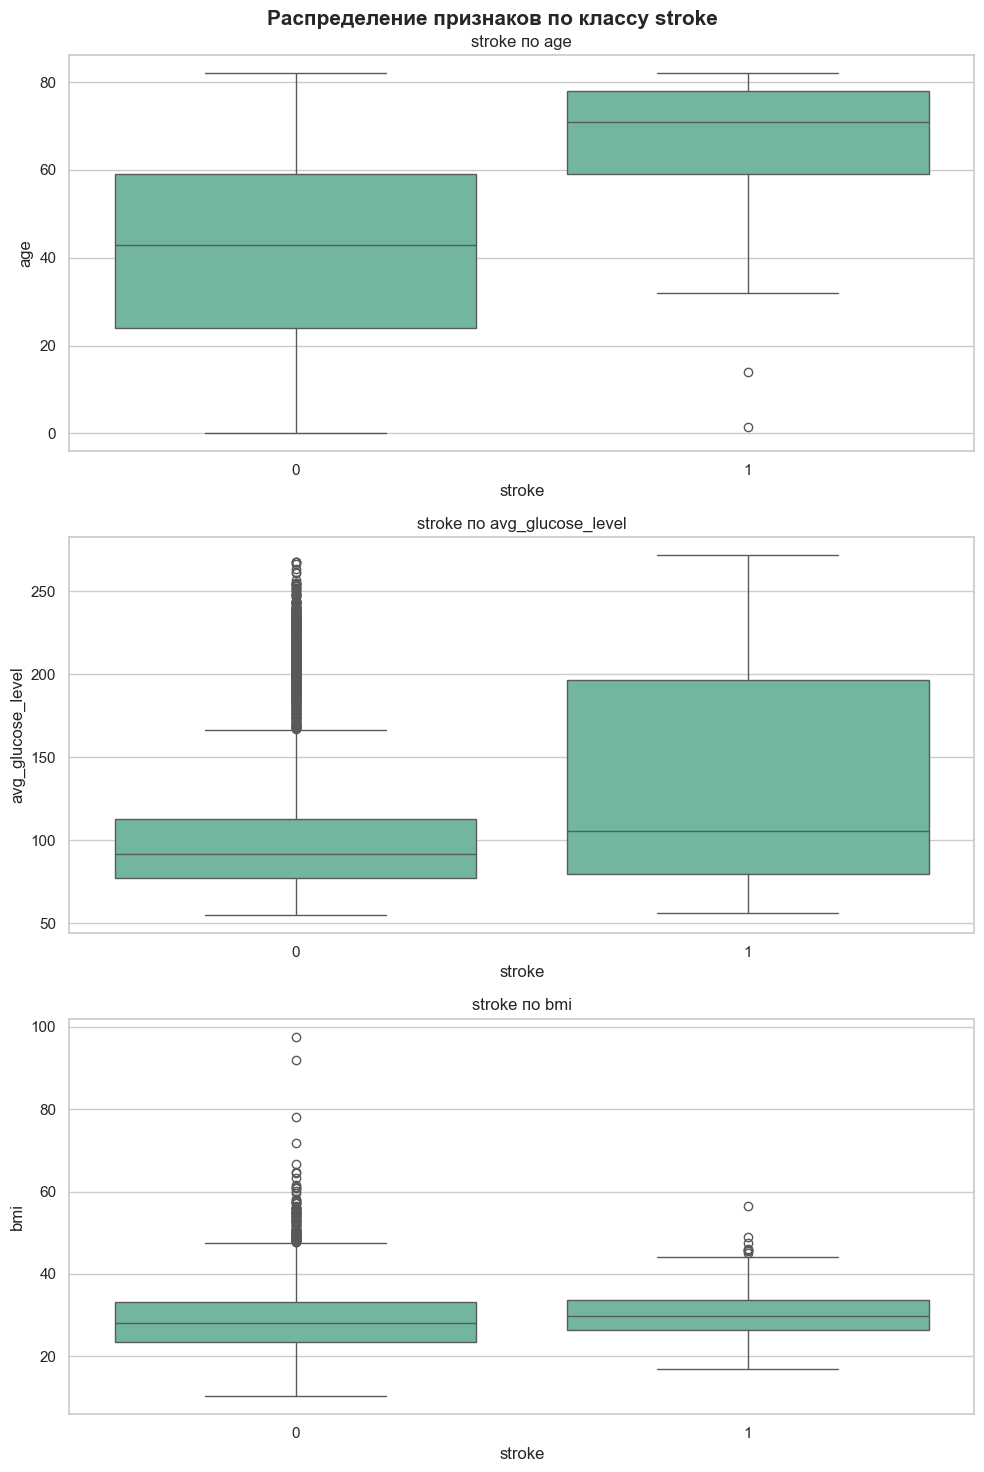

In [13]:
fig, ax = plt.subplots(3, 1,figsize=(10,15))

sns.boxplot(
    data=df,
    x='stroke',
    y='age',
    ax=ax[0]
)
ax[0].set_title('stroke по age')

sns.boxplot(
    data=df,
    x='stroke',
    y='avg_glucose_level',
    ax=ax[1]
)
ax[1].set_title('stroke по avg_glucose_level')

sns.boxplot(
    data=df,
    x='stroke',
    y='bmi',
    ax=ax[2]
)
ax[2].set_title('stroke по bmi')

plt.suptitle('Распределение признаков по классу stroke', fontsize=15, fontweight=600)

plt.tight_layout()
plt.show()

### Выводы по распределениям:
- **Инсульт появляется** у людей `старше 35 лет`, всего у 2х людей в раннем возрасте, но это скорее исключение из правил, логично ведь чем страше человек становится, тем вероятность инсульта повышается
- **Уровень глюкозы у людей с инсультом как правило выше**, это особенно заметно по верхней границе IQR для обоих классов
- А вот по ИМТ по этому графику не видно какой-то логики, медианы между классами примерно одинаковые, распределения похожи и более того, у людей без инсульта бывает ИМТ выше, чем у людей с инсультом

Посмотрим распределения категориальных признаков по целевой переменной:


gender


stroke,0,1
gender,,
Female,0.952906,0.047094
Male,0.948936,0.051064
Other,1.000000,0.000000



hypertension


stroke,0,1
hypertension,,
0,0.960321,0.039679
1,0.867470,0.132530



heart_disease


stroke,0,1
heart_disease,,
0,0.958213,0.041787
1,0.829710,0.170290



ever_married


stroke,0,1
ever_married,,
No,0.983495,0.016505
Yes,0.934387,0.065613



work_type


stroke,0,1
work_type,,
Govt_job,0.949772,0.050228
Never_worked,1.000000,0.000000
Private,0.949060,0.050940
Self-employed,0.920635,0.079365
children,0.997089,0.002911



Residence_type


stroke,0,1
Residence_type,,
Rural,0.954654,0.045346
Urban,0.947997,0.052003



smoking_status


stroke,0,1
smoking_status,,
Unknown,0.969560,0.030440
formerly smoked,0.920904,0.079096
never smoked,0.952431,0.047569
smokes,0.946768,0.053232


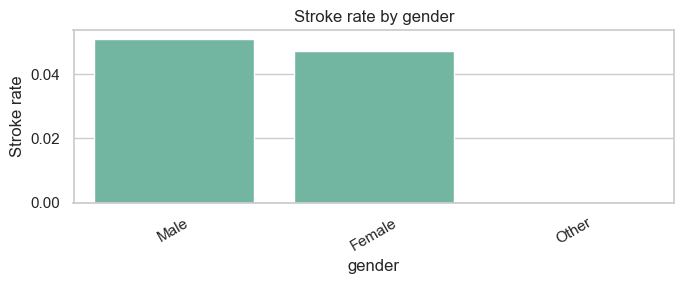

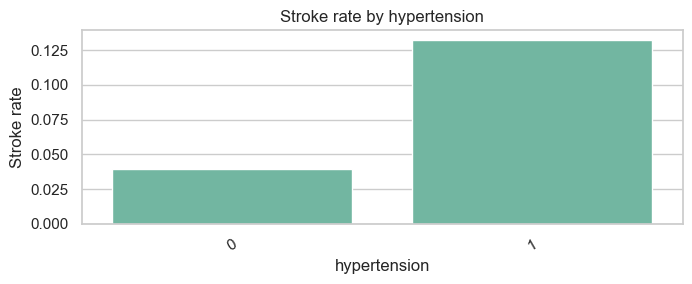

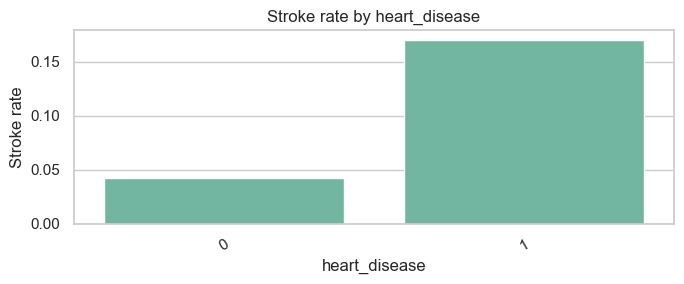

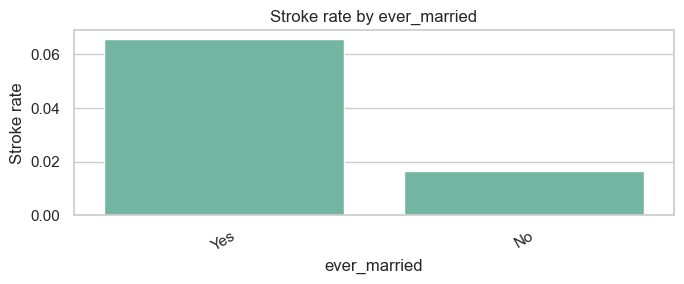

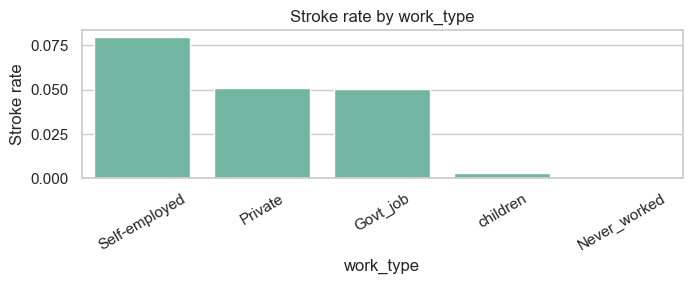

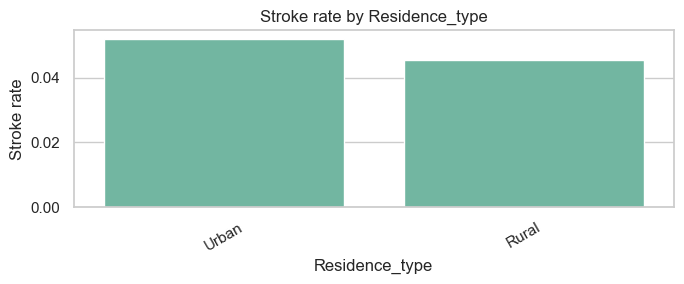

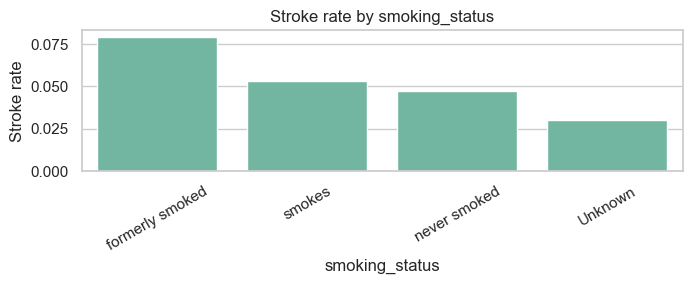

In [14]:
cat_cols = [
    'gender',
    'hypertension',
    'heart_disease',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

for col in cat_cols:
    print(f'\n{col}')
    display(
        pd.crosstab(
            df[col],
            df['stroke'],
            normalize='index'
        )
    )

for col in cat_cols:
    stroke_rate = (
        df.groupby(col, observed=True)['stroke']
        .mean()
        .sort_values(ascending=False)
        .reset_index()
    )

    plt.figure(figsize=(7, 3))

    sns.barplot(
        data=stroke_rate,
        x=col,
        y='stroke'
    )

    plt.title(f'Stroke rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Stroke rate')

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

### Выводы по отношениям класса в категориальных признаках:
- `По полу` особых **различий нет** в отношении долей с инсультом
- Доля пациентов с инсультом среди людей `с гипертонией` примерно **в 4 раза выше**, чем среди людей без гипертонии
- Доля пациентов с инсультом среди людей `с болезнями сердца` **в 4 раза выше**, чем среди людей без болезней
- У людей, `состоявших в браке` инсульт случался **в 4 разе чаще**, интересное наблюдение, возможно люди, которые состоят в браке просто статистически старше людей не в браке
- Интересное наблюдение, что `у людей, которые никогда не работали`, вообще **не было инсульта** в наших данных, так же у детей почти не было, было пару случаев, но это скорее исключение из правил, в остальном тип работы не особо влияет на инсульт, но стоит проверить количество пациентов никогда не работавших
- `У деревенских и городских` людей инсульт случался примерно **в равном отношении**
- Интересное наблюдение, что у `постоянно курящих` людей инсульт случался примерно **в таком же отношении**, как и у `никогда не куривших людей`, а **чаще всего инсульт случался** у людей, которые `курили, но бросили`, изучим это еще отдельно

In [15]:
df.groupby('ever_married')['age'].median()

ever_married
No     18.0
Yes    54.0
Name: age, dtype: float64

Да, люди, которые состояли в браке намного старше людей, которые не состояли в браке, поэтому инсульт и происходил чаще у более возрослых людей, по сути у этого признака связь с stroke идет через возраст, поэтому мы удалим этот признак, он нам не понадобится, у нас есть отдельный признак возраста, который показывает лучше связь

In [16]:
df['work_type'].value_counts()

work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Людей, которые никогда не работали довольно малое количество, поэтому-то и получилось так, что у них не было инсульта, надо будет учесть это, чтобы наша моделька не делала сразу выводов по этому признаку

In [17]:
df['smoking_status'].value_counts()

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

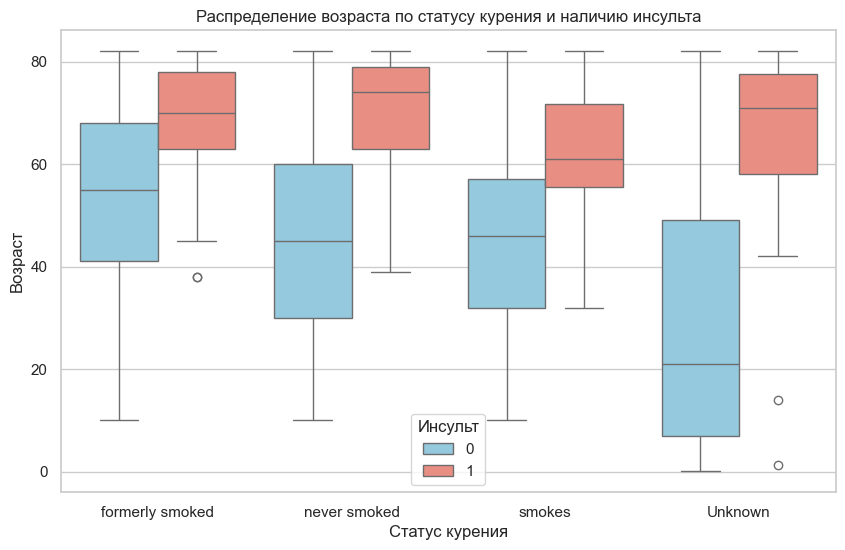

In [18]:
sns.boxplot(
    data=df,
    x='smoking_status',
    y='age',
    hue='stroke',
    palette={
        0: 'skyblue',
        1: 'salmon'
    }
)

plt.title('Распределение возраста по статусу курения и наличию инсульта')
plt.xlabel('Статус курения')
plt.ylabel('Возраст')

plt.legend(title='Инсульт')

plt.show()

У пациентов, которые курили раньше, но бросили средний возраст выше, чем у курящих, но разница в возрасте не сильно велика

Посмотрим матрицу корреляций Спирмана, именно Спирмана, поскольку есть немалое количество выбросов:

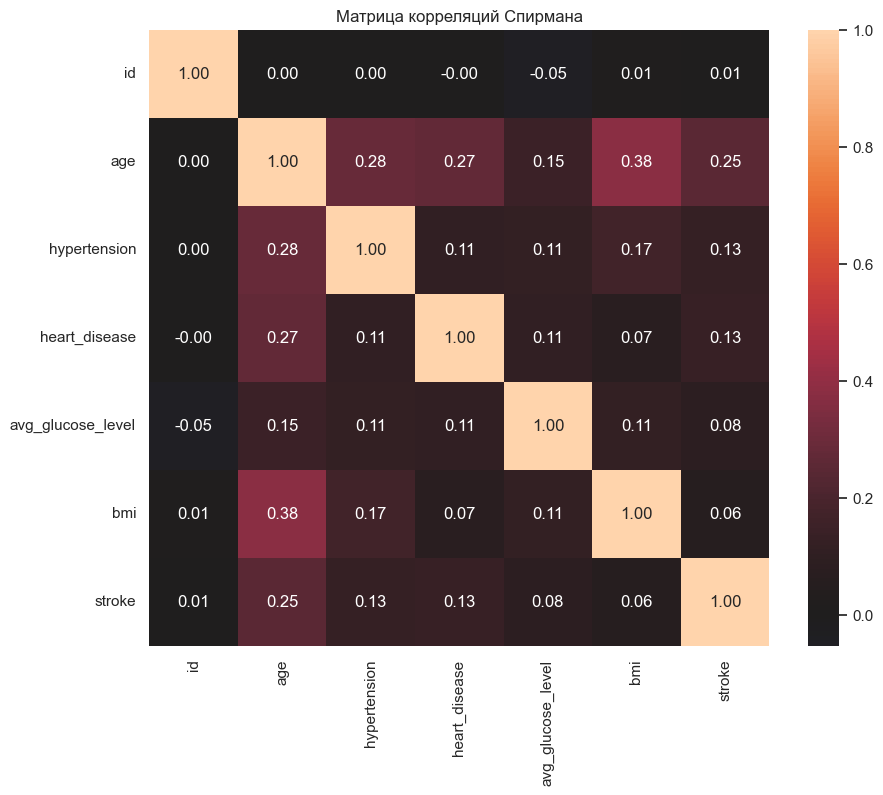

In [19]:
num_cols = df.select_dtypes(include='number').columns

corr = df[num_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    center=0
)

plt.title('Матрица корреляций Спирмана')
plt.show()

Сильных корреляций между признаками не обнаружено

Максимальный коэффициент корреляции не превышает 0.37, что указывает на отсутствие выраженных линейных/монотонных зависимостей между большинством числовых признаков

In [20]:
df.duplicated().sum()

np.int64(0)

Дубликатов в данных не обнаружено

In [21]:
df.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Единственный признак, имеющий в себе пропуски это bmi (Индекс массы тела), посмотрим его распределение:

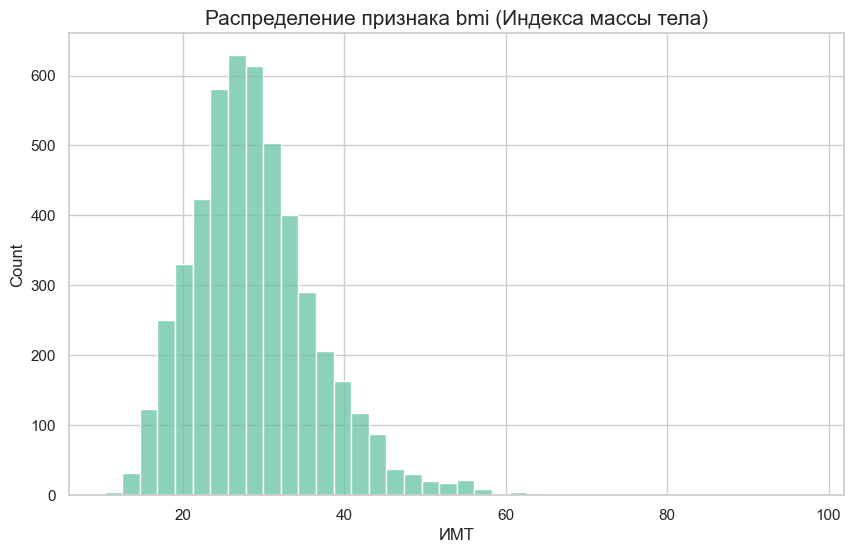

In [22]:
sns.histplot(df['bmi'], bins=40)

plt.title('Распределение признака bmi (Индекса массы тела)', fontsize=15)
plt.xlabel('ИМТ')

plt.show()

Распределение нормальное, большая часть значений лежит в диапазоне 20-36, при том, что нормой является ИМТ в диапазоне 18.5–25, то есть в наших данных есть довольно много людей с небольшим избытком веса

In [23]:
(df['bmi'].isna().sum() / df.shape[0]) * 100

np.float64(3.9334637964774952)

В признаке bmi пропущено около 4% от всех данных, это не особо много

In [24]:
q1, q3 = df["bmi"].quantile([0.25, 0.75])
iqr = q3 - q1

lo = q1 - 1.5 * iqr
hi = q3 + 1.5 * iqr

outliers = df.loc[(df["bmi"] < lo) | (df["bmi"] > hi), "bmi"]

print(f"Q1   = {q1:.2f}")
print(f"Q3   = {q3:.2f}")
print(f"IQR  = {iqr:.2f}")
print(f"границы = [{lo:.2f}, {hi:.2f}]")
print(f"выбросов: {len(outliers)} ({len(outliers) / df['bmi'].notna().sum():.2%})")

Q1   = 23.50
Q3   = 33.10
IQR  = 9.60
границы = [9.10, 47.50]
выбросов: 110 (2.24%)


Есть немалое количество выбросов, посмотрим чуть позже выбросы и в других числовых признаках

In [25]:
patients_with_obesity = df['bmi'] > 30

(df[patients_with_obesity].shape[0] / df.shape[0]) * 100

37.04500978473581

In [26]:
patients_very_thin = df['bmi'] < 18.5

(df[patients_very_thin].shape[0] / df.shape[0]) * 100

6.594911937377692

`37%` человек из данных имеют ИМТ **более 30**, что считается **ожирением**, это довольно большое количество

А вот **слишком худых**, имеющих ИМТ меньше 18.5 **заметно меньше**, менее 7%

Посмотрим есть ли какая-то логика пропусков в bmi:

In [27]:
df[df['bmi'].isna()]

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
13,8213,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1
19,25226,Male,57.0,0,1,No,Govt_job,Urban,217.08,NaN,Unknown,1
27,61843,Male,58.0,0,0,Yes,Private,Rural,189.84,NaN,Unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5039,42007,Male,41.0,0,0,No,Private,Rural,70.15,NaN,formerly smoked,0
5048,28788,Male,40.0,0,0,Yes,Private,Urban,191.15,NaN,smokes,0
5093,32235,Female,45.0,1,0,Yes,Govt_job,Rural,95.02,NaN,smokes,0
5099,7293,Male,40.0,0,0,Yes,Private,Rural,83.94,NaN,smokes,0


Нет, на первый взгляд пропуски ИМТ есть у совершенно различных людей и никакой логики здесь не видно

Попробуем найти лучшие показатели на основе других имеющихся признаков

по типу занятости:

In [28]:
df.groupby('work_type')['bmi'].median()

work_type
Govt_job         29.40
Never_worked     23.15
Private          28.90
Self-employed    29.40
children         18.90
Name: bmi, dtype: float64

Для просмотра по возрасту будет удобнее для начала возраст преобразовать в интервалы, а затем уже смотреть по ним средние значения

In [29]:
bins = [0, 18, 30, 45, 60, 75, 100]
labels = ['0-18', '19-30', '31-45', '46-60', '61-75', '76+']

df['age_group'] = pd.cut(
    df['age'],
    bins=bins,
    labels=labels
)

df.groupby('age_group', observed=True)['bmi'].median()

age_group
0-18     20.1
19-30    26.6
31-45    30.0
46-60    30.3
61-75    29.7
76+      28.1
Name: bmi, dtype: float64

In [30]:
df['bmi'].isna().sum()

np.int64(201)

Наиболее надежные значения для заполнения пропусков bmi мы можем получить сгруппировав 3 имеющихся признака: 
- `age_group`
- `gender`
- `work_type`

Так же для страховки сделаем **ограничение**, что мы заполняем полученным значением после группировки только если по нему имеется **более 10 наблюдений**, иначе если у нас будет менее 3 наблюдений значения будут нестабильны и ненадежны, если останутся пропуски будем группировать по 2-ум признакам и т д

In [31]:
group = df.groupby(
    ['age_group', 'gender', 'work_type'],
    observed=True
)['bmi']

stats = group.agg(['median', 'count'])

bmi_median = group.transform('median')
bmi_count = group.transform('count')

more_10 = bmi_count >= 10

df.loc[
    df['bmi'].isna() & more_10,
    'bmi'
] = bmi_median

In [32]:
df['bmi'].isna().sum()

np.int64(0)

Уже после первой группировки все пустые значения в признаке bmi заполнились, отлично

In [33]:
df.groupby('work_type')['stroke'].value_counts()

work_type      stroke
Govt_job       0          624
               1           33
Never_worked   0           22
Private        0         2776
               1          149
Self-employed  0          754
               1           65
children       0          685
               1            2
Name: count, dtype: int64

`work_type_children` имеет слишком малое количество положительных результатов

### Удаление ненужных признаков:

In [34]:
df = df.drop(columns=['id', 'age_group', 'ever_married'])
df.head(3)

,gender,age,hypertension,heart_disease,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Self-employed,Rural,202.21,29.3,never smoked,1
2,Male,80.0,0,1,Private,Rural,105.92,32.5,never smoked,1


### Обработка категориальных признаков

In [35]:
df['gender'].value_counts()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Всего 1 наблюдение с `gender == Other`, лучше не будем смотреть на него, это слишком малое количество наблюдений, оно может только **запутать модель**

In [36]:
df = df[df['gender'] != 'Other'].copy()
df['gender'].value_counts()

gender
Female    2994
Male      2115
Name: count, dtype: int64

## Кодирование категориальных признаков

### Бинарные признаки

**gender**
->
**is_male**
->
`0 / 1`

**Residence_type**
->
**is_urban**
->
`0 / 1`

OneHotEncoder для остальных применим внутри пайплайна

In [37]:
df['is_male'] = (df['gender'] == 'Male').astype(int)
df['is_urban'] = (df['Residence_type'] == 'Urban').astype(int)

Удаляем исходные признаки, которые мы закодировали:

In [38]:
df = df.drop(
    columns=['gender', 'Residence_type']
)

In [39]:
df.head(5)

,age,hypertension,heart_disease,work_type,avg_glucose_level,bmi,smoking_status,stroke,is_male,is_urban
0,67.0,0,1,Private,228.69,36.6,formerly smoked,1,1,1
1,61.0,0,0,Self-employed,202.21,29.3,never smoked,1,0,0
2,80.0,0,1,Private,105.92,32.5,never smoked,1,1,0
3,49.0,0,0,Private,171.23,34.4,smokes,1,0,1
4,79.0,1,0,Self-employed,174.12,24.0,never smoked,1,0,0


### Train / Test Split

In [40]:
X = df.drop(columns='stroke').copy()
y = df['stroke']

In [41]:
X

,age,hypertension,heart_disease,work_type,avg_glucose_level,bmi,smoking_status,is_male,is_urban
0,67.0,0,1,Private,228.69,36.6,formerly smoked,1,1
1,61.0,0,0,Self-employed,202.21,29.3,never smoked,0,0
2,80.0,0,1,Private,105.92,32.5,never smoked,1,0
3,49.0,0,0,Private,171.23,34.4,smokes,0,1
4,79.0,1,0,Self-employed,174.12,24.0,never smoked,0,0
...,...,...,...,...,...,...,...,...,...
5105,80.0,1,0,Private,83.75,28.1,never smoked,0,1
5106,81.0,0,0,Self-employed,125.20,40.0,never smoked,0,1
5107,35.0,0,0,Self-employed,82.99,30.6,never smoked,0,0
5108,51.0,0,0,Private,166.29,25.6,formerly smoked,1,0


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [43]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

### Preprocessing

In [44]:
numeric_features = [
    'age',
    'avg_glucose_level',
    'bmi',
    'hypertension',
    'heart_disease',
    'is_male',
    'is_urban'
]

categorical_features = [
    'work_type',
    'smoking_status'
]

In [45]:
numeric_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

## Baseline — Logistic Regression

В качестве baseline выберем Logistic Regression, поскольку:

- целевая переменная `stroke` является бинарной (`0 / 1`);
- модель хорошо подходит для бинарной классификации;
- является относительно простой и интерпретируемой;
- позволяет получить понятную отправную точку для сравнения с более сложными моделями;
- хорошо работает с числовыми и One-Hot закодированными признаками после масштабирования.

В дальнейшем сравним её результаты с более сложными моделями и проверим, дают ли они существенное улучшение качества.

In [46]:
logreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])
logreg_pipeline

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [47]:
logreg_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [48]:
y_val_proba = logreg_pipeline.predict_proba(X_val)[:, 1]
y_proba = logreg_pipeline.predict_proba(X_test)[:, 1]
y_pred = logreg_pipeline.predict(X_test)

In [49]:
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

Accuracy: 0.9523
Precision: 1.0000
Recall: 0.0161
F1: 0.0317
ROC-AUC: 0.8420
PR-AUC: 0.2667


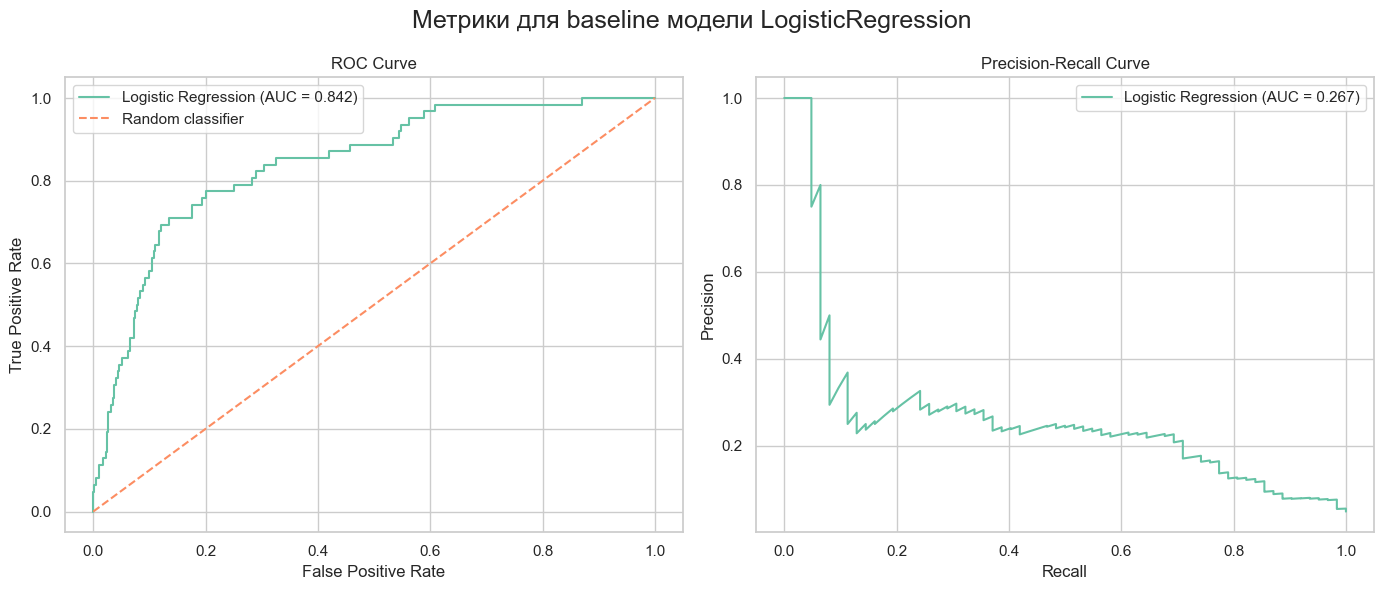

In [50]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
    'PR-AUC': average_precision_score(y_test, y_proba)
}

for metric, value in metrics.items():
    print(f'{metric}: {value:.4f}')

fpr, tpr, _ = roc_curve(y_test, y_proba)
precision, recall, _ = precision_recall_curve(y_test, y_proba)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})'
)

ax[0].plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].set_title('ROC Curve')
ax[0].legend()


ax[1].plot(
    recall,
    precision,
    label=f'Logistic Regression (AUC = {pr_auc:.3f})'
)

ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall Curve')
ax[1].legend()

plt.suptitle('Метрики для baseline модели LogisticRegression', fontsize=18)

plt.tight_layout()
plt.show()

### Результаты первого обучения baseline-модели

После первого обучения Logistic Regression получили следующие результаты:

- **Accuracy = 0.9523**
- **Precision = 1.0000**
- **Recall = 0.0161**
- **F1 = 0.0317**
- **ROC-AUC = 0.8442**
- **PR-AUC = 0.2653**

На первый взгляд Accuracy и ROC-AUC выглядят достаточно высокими, однако из-за сильного дисбаланса классов они не полностью отражают качество обнаружения редкого положительного класса

Особенно заметен очень низкий **Recall = 0.0161**. Это означает, что при стандартном `threshold = 0.5` модель обнаруживает лишь небольшую часть пациентов с инсультом

Для нашей задачи это критично, поскольку **FN (False Negative)** — случаи, когда модель не обнаружила инсульт — для нас важнее, чем **FP (False Positive)**

Поэтому следующим шагом попробуем изменить порог классификации и посмотреть, как это повлияет на Recall и Precision

### Изменение порога классификации

По умолчанию Logistic Regression использует `threshold = 0.5`: если вероятность инсульта выше 0.5, модель относит пациента к классу `1`.

Для нашей задачи это не лучший вариант, поскольку классы сильно несбалансированы, а **пропустить пациента с потенциальным инсультом (FN) для нас важнее, чем ошибочно отнести здорового пациента к группе риска (FP)**.

Поэтому мы снижаем threshold. Это позволяет модели чаще относить пациентов к положительному классу и тем самым повысить **Recall**.

Подберем наиболее подходящий порог для нашей задачи:

In [51]:
thresholds = np.arange(0.05, 0.51, 0.05)

for threshold in thresholds:
    y_pred_threshold = (y_val_proba >= threshold).astype(int)

    precision = precision_score(y_val, y_pred_threshold)
    recall = recall_score(y_val, y_pred_threshold)
    f1 = f1_score(y_val, y_pred_threshold)

    print(
        f'Threshold: {threshold:.2f} | '
        f'Precision: {precision:.3f} | '
        f'Recall: {recall:.3f} | '
        f'F1: {f1:.3f}'
    )

Threshold: 0.05 | Precision: 0.139 | Recall: 0.865 | F1: 0.240
Threshold: 0.10 | Precision: 0.152 | Recall: 0.568 | F1: 0.240
Threshold: 0.15 | Precision: 0.122 | Recall: 0.270 | F1: 0.168
Threshold: 0.20 | Precision: 0.132 | Recall: 0.135 | F1: 0.133
Threshold: 0.25 | Precision: 0.182 | Recall: 0.108 | F1: 0.136
Threshold: 0.30 | Precision: 0.214 | Recall: 0.081 | F1: 0.118
Threshold: 0.35 | Precision: 0.333 | Recall: 0.027 | F1: 0.050
Threshold: 0.40 | Precision: 0.000 | Recall: 0.000 | F1: 0.000
Threshold: 0.45 | Precision: 0.000 | Recall: 0.000 | F1: 0.000
Threshold: 0.50 | Precision: 0.000 | Recall: 0.000 | F1: 0.000


### Изменение порога классификации

По умолчанию Logistic Regression использует `threshold = 0.5`: если вероятность инсульта выше 0.5, модель относит пациента к классу `1`.

Для нашей задачи такой порог приводит к очень низкому Recall, поэтому мы исследовали, как изменение threshold влияет на Precision и Recall. Для выбора порога использовали **validation-выборку**, не затрагивая тестовую выборку.

Получили следующие результаты:

* `threshold = 0.05`: Precision = `0.139`, Recall = `0.865`, F1 = `0.240`
* `threshold = 0.10`: Precision = `0.152`, Recall = `0.568`, F1 = `0.240`
* `threshold = 0.15`: Precision = `0.122`, Recall = `0.270`, F1 = `0.168`
* `threshold = 0.20`: Precision = `0.132`, Recall = `0.135`, F1 = `0.133`
* `threshold = 0.25`: Precision = `0.182`, Recall = `0.108`, F1 = `0.136`
* `threshold = 0.30`: Precision = `0.214`, Recall = `0.081`, F1 = `0.118`

При стандартном `threshold = 0.5` модель практически не определяет положительный класс. На validation-выборке Recall равен `0.000`.

Снижение threshold позволяет значительно увеличить Recall, однако одновременно снижается Precision. Например, при `threshold = 0.05` Recall достигает `0.865`, но Precision составляет всего `0.139`. При `threshold = 0.10` Recall снижается до `0.568`, зато Precision немного увеличивается до `0.152`.

В рамках нашей задачи пропустить потенциальный случай инсульта (FN) важнее, чем дополнительно получить ложное срабатывание (FP), поэтому при выборе threshold мы уделяем особое внимание Recall.

На данном этапе для baseline выберем `threshold = 0.05`, поскольку он обеспечивает наиболее высокий Recall (`0.865`) при таком же значении F1 (`0.240`), как и `threshold = 0.10`.

После выбора threshold финальные метрики модели будем рассчитывать на **test-выборке**, которая не использовалась ни для обучения модели, ни для выбора порога.


Теперь посмотрим, как поменялись метрики с новым порогом:

In [52]:
threshold = 0.05

y_pred_threshold = (y_proba >= threshold).astype(int)

metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_threshold),
    'Precision': precision_score(y_test, y_pred_threshold),
    'Recall': recall_score(y_test, y_pred_threshold),
    'F1': f1_score(y_test, y_pred_threshold)
}

for metric, value in metrics.items():
    print(f'{metric}: {value:.4f}')

Accuracy: 0.7269
Precision: 0.1273
Recall: 0.7903
F1: 0.2192


### Результаты после изменения threshold

После снижения `threshold` с `0.5` до `0.05` получили:

- **Accuracy = 0.7269**
- **Precision = 0.1273**
- **Recall = 0.7903**
- **F1 = 0.2192**

Основное улучшение произошло по **Recall**: он вырос с `0.0161` до `0.7903`. Это означает, что модель стала обнаруживать значительно больше случаев инсульта

При этом Precision снизился, а количество ложноположительных предсказаний увеличилось. Для нашей задачи такой компромисс приемлем, поскольку пропуск положительного случая (`FN`) для нас важнее, чем ложное срабатывание (`FP`)

In [53]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'XGBoost': XGBClassifier(
        n_estimators=300,
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ),

    'LightGBM': LGBMClassifier(
        n_estimators=300,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),

    'CatBoost': CatBoostClassifier(
        iterations=300,
        random_state=42,
        verbose=False
    )
}

Теперь создаём Pipeline для каждой модели:

In [54]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

Обучаем и сразу собираем метрики:

In [55]:
results = {}

for name, pipeline in pipelines.items():

    print(f'Обучение: {name}')

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba)
    }

    print(
        f"Accuracy:  {results[name]['Accuracy']:.4f}\n"
        f"Precision: {results[name]['Precision']:.4f}\n"
        f"Recall:    {results[name]['Recall']:.4f}\n"
        f"F1:        {results[name]['F1']:.4f}\n"
        f"ROC-AUC:   {results[name]['ROC-AUC']:.4f}\n"
        f"PR-AUC:    {results[name]['PR-AUC']:.4f}\n"
    )

Обучение: Logistic Regression
Accuracy:  0.9523
Precision: 1.0000
Recall:    0.0161
F1:        0.0317
ROC-AUC:   0.8420
PR-AUC:    0.2667

Обучение: Decision Tree
Accuracy:  0.9022
Precision: 0.0800
Recall:    0.0968
F1:        0.0876
ROC-AUC:   0.5200
PR-AUC:    0.0516

Обучение: Random Forest
Accuracy:  0.9515
Precision: 0.5000
Recall:    0.0161
F1:        0.0312
ROC-AUC:   0.7947
PR-AUC:    0.2104

Обучение: XGBoost
Accuracy:  0.9405
Precision: 0.2500
Recall:    0.1129
F1:        0.1556
ROC-AUC:   0.7699
PR-AUC:    0.1882

Обучение: LightGBM
Accuracy:  0.9437
Precision: 0.2727
Recall:    0.0968
F1:        0.1429
ROC-AUC:   0.7878
PR-AUC:    0.1789

Обучение: CatBoost
Accuracy:  0.9491
Precision: 0.2857
Recall:    0.0323
F1:        0.0580
ROC-AUC:   0.8216
PR-AUC:    0.2019



А теперь графики ROC + PR для всех моделей:

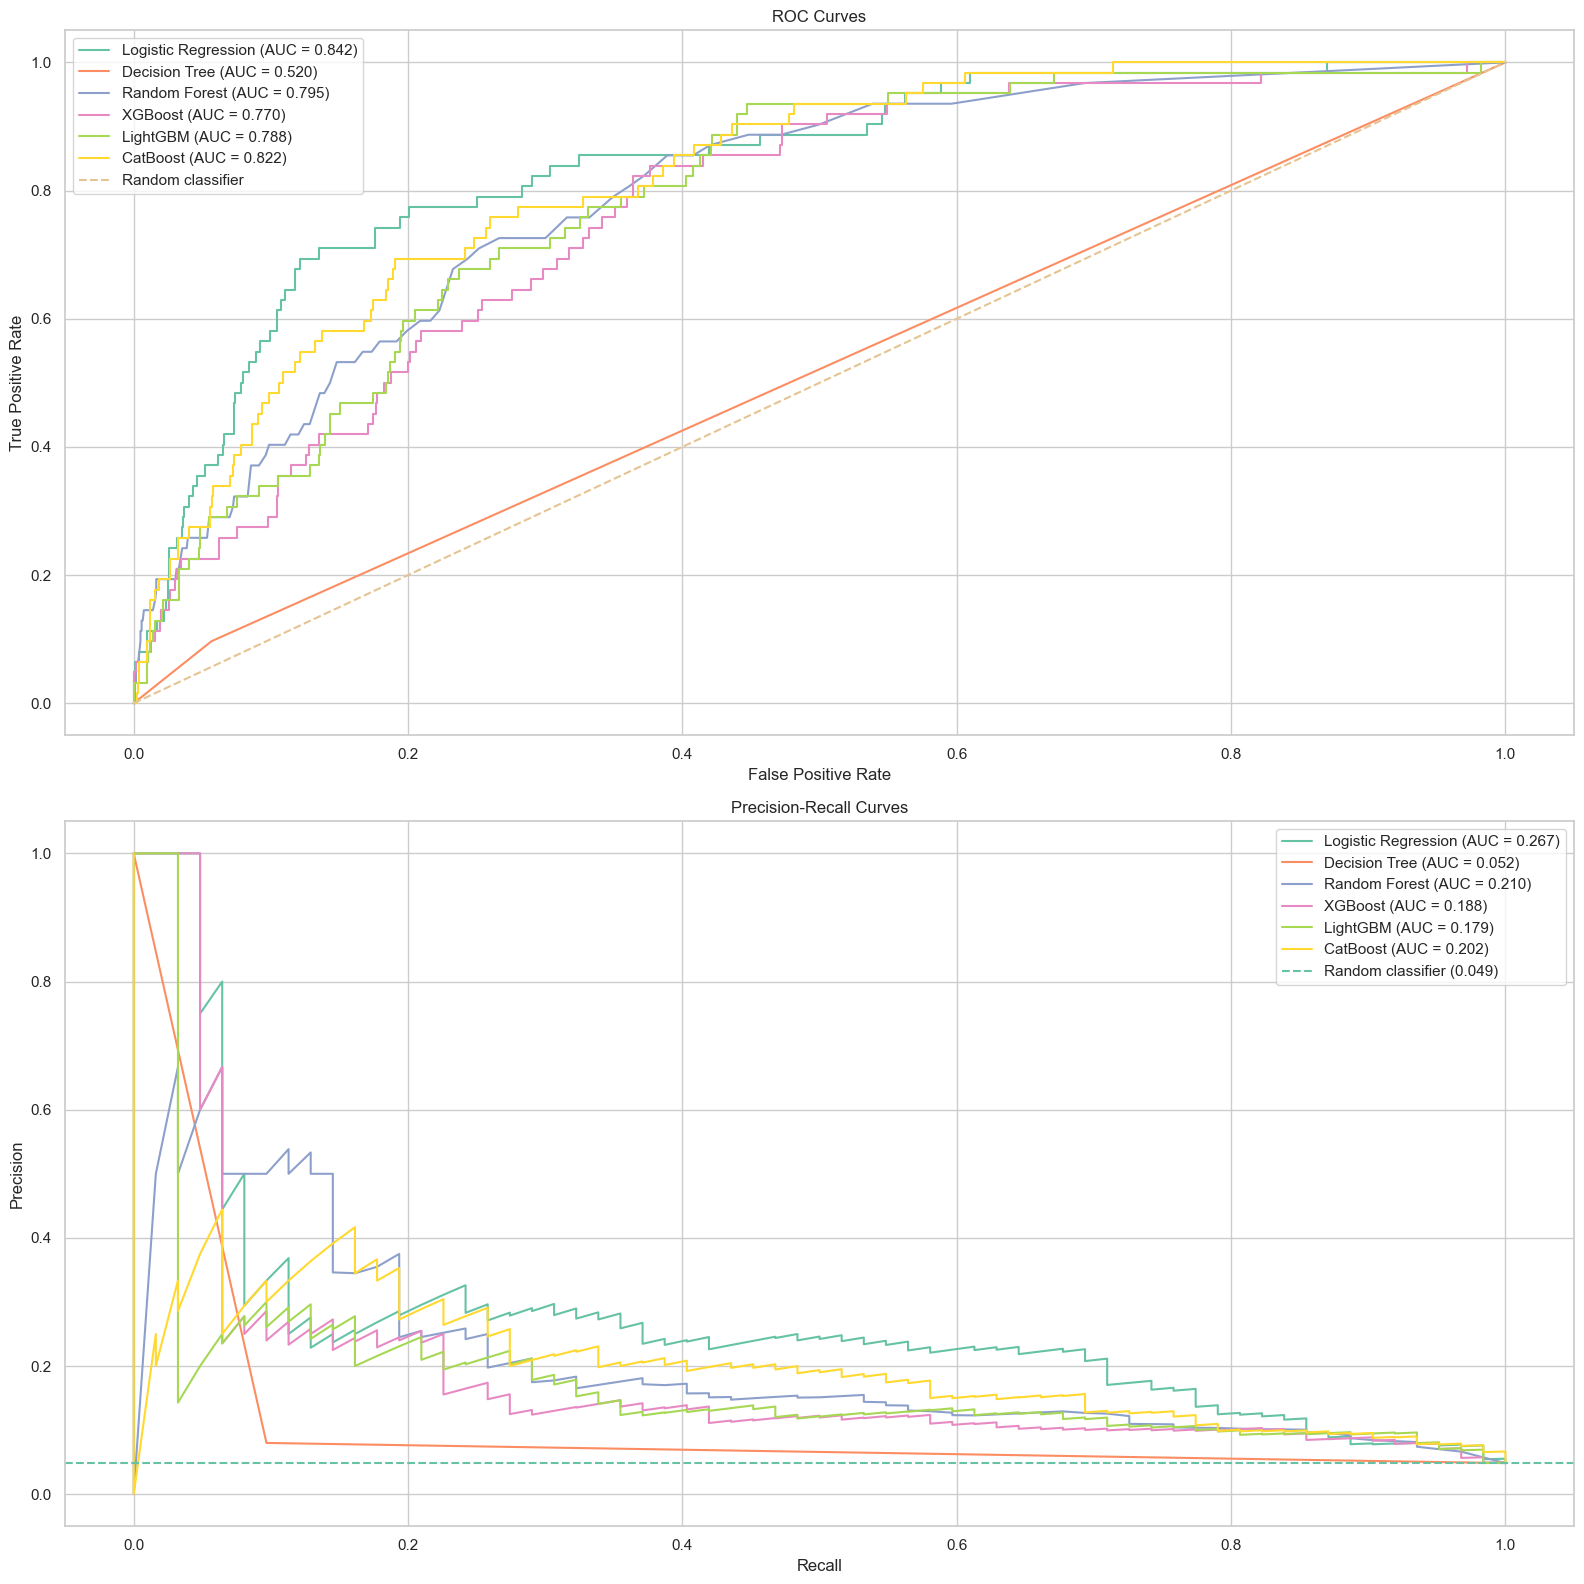

In [56]:
fig, ax = plt.subplots(2, 1, figsize=(16, 16))

for name, pipeline in pipelines.items():

    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_proba)

    ax[0].plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})'
    )

    # PR
    precision, recall, _ = precision_recall_curve(
        y_test,
        y_proba
    )

    ax[1].plot(
        recall,
        precision,
        label=f'{name} (AUC = {average_precision_score(y_test, y_proba):.3f})'
    )


# Random classifier для ROC
ax[0].plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

# Random baseline для PR
baseline = y_test.mean()

ax[1].axhline(
    baseline,
    linestyle='--',
    label=f'Random classifier ({baseline:.3f})'
)


# ROC
ax[0].set_title('ROC Curves')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].legend()


# PR
ax[1].set_title('Precision-Recall Curves')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()


plt.tight_layout()
plt.show()

## Сравнение моделей

На тестовой выборке при стандартном пороге `0.5` получили:

| Модель                  |  Accuracy | Precision |    Recall |        F1 |   ROC-AUC |    PR-AUC |
| ----------------------- | --------: | --------: | --------: | --------: | --------: | --------: |
| **Logistic Regression** | **0.952** | **1.000** |     0.016 |     0.032 | **0.844** | **0.265** |
| Random Forest           |     0.952 |     0.500 |     0.016 |     0.031 |     0.795 |     0.210 |
| CatBoost                |     0.949 |     0.286 |     0.032 |     0.058 |     0.822 |     0.202 |
| XGBoost                 |     0.941 |     0.250 | **0.113** | **0.156** |     0.770 |     0.188 |
| LightGBM                |     0.944 |     0.273 |     0.097 |     0.143 |     0.788 |     0.179 |
| Decision Tree           |     0.902 |     0.080 |     0.097 |     0.088 |     0.520 |     0.052 |

### Промежуточные выводы

По результатам первичного сравнения **Logistic Regression показывает лучшие значения PR-AUC и ROC-AUC**, однако окончательно выбирать модель пока рано.

Для дальнейшей проверки оставляем следующие модели:

* Logistic Regression
* CatBoost
* XGBoost
* Random Forest
* LightGBM

Модель **Decision Tree** исключаем из дальнейшего сравнения.

Следующим этапом проведём **кросс-валидацию** выбранных кандидатов и сравним средние значения `PR-AUC` и `ROC-AUC`, после чего определим итоговую модель.


### Cross-Validation
Для оценки стабильности моделей используем **10-fold Stratified Cross-Validation**.

Для сравнения моделей используем **PR-AUC (Average Precision)** как основную метрику из-за сильного дисбаланса классов.

In [57]:
models_cv = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'XGBoost': XGBClassifier(
        n_estimators=300,
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ),

    'LightGBM': LGBMClassifier(
        n_estimators=300,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),

    'CatBoost': CatBoostClassifier(
        iterations=300,
        random_state=42,
        verbose=False
    )
}

models_cv

{'Logistic Regression': LogisticRegression(max_iter=1000),
 'Random Forest': RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=None, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=None, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=None, n_estimators=300, n_jobs=-1,
               num_parallel_tree=None, ...),
 'LightGBM': LGBMClassifier(n_estimators=300, n_jobs=

In [58]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv

StratifiedKFold(n_splits=10, random_state=42, shuffle=True)

In [59]:
cv_results = []

for name, model in models_cv.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    results = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='average_precision',
        n_jobs=-1
    )

    scores = results['test_score']

    cv_results.append({
        'Model': name,
        'Fold 1': scores[0],
        'Fold 2': scores[1],
        'Fold 3': scores[2],
        'Fold 4': scores[3],
        'Fold 5': scores[4],
        'Fold 6': scores[5],
        'Fold 7': scores[6],
        'Fold 8': scores[7],
        'Fold 9': scores[8],
        'Fold 10': scores[9],
        'Mean PR-AUC': scores.mean(),
        'Std PR-AUC': scores.std()
    })

cv_results = pd.DataFrame(cv_results)

cv_results = cv_results.sort_values(
    'Mean PR-AUC',
    ascending=False
).reset_index(drop=True)

cv_results

,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Fold 6,Fold 7,Fold 8,Fold 9,Fold 10,Mean PR-AUC,Std PR-AUC
0,Logistic Regression,0.266407,0.093489,0.191437,0.278643,0.183917,0.303720,0.164934,0.196173,0.126675,0.434401,0.223980,0.094257
1,LightGBM,0.298514,0.144517,0.271131,0.196934,0.254240,0.199921,0.139465,0.184539,0.170127,0.233839,0.209323,0.050859
2,XGBoost,0.225125,0.136466,0.181240,0.154693,0.209286,0.248378,0.119823,0.186685,0.153623,0.306417,0.192174,0.053822
3,CatBoost,0.182075,0.114405,0.233034,0.163971,0.155366,0.189816,0.230018,0.176800,0.151807,0.190604,0.178789,0.033889
4,Random Forest,0.168975,0.070132,0.193048,0.173015,0.161429,0.228513,0.180689,0.153324,0.167790,0.154467,0.165138,0.037966


### Вывод

По результатам **5-fold и 10-fold Cross-Validation** Logistic Regression показала наибольшее среднее значение **PR-AUC** среди рассмотренных моделей.

В 10-fold CV:

* **Logistic Regression:** `PR-AUC = 0.224 ± 0.094`
* LightGBM: `0.209 ± 0.051`
* XGBoost: `0.192 ± 0.054`
* CatBoost: `0.179 ± 0.034`
* Random Forest: `0.165 ± 0.038`

Таким образом, для дальнейшей работы **выбираем Logistic Regression**. Следующим этапом проведём настройку её гиперпараметров и после этого подберём оптимальный порог классификации.

Получается **Logistic Regression** у нас и по CV лучший, и при этом простой и хорошо интерпретируемый - для медицинских данных вообще удобно, здорово


### Оптимизация гиперпарапетров

Для Logistic Regression с помощью **Optuna** подбираем следующие параметры:

* **`C`** - обратная сила регуляризации. Чем меньше `C`, тем сильнее регуляризация. Подбор этого параметра позволяет найти оптимальный баланс между сложностью модели и переобучением

* **`class_weight`** - веса классов. Проверяем `None` и `balanced`, поскольку в датасете наблюдается сильный дисбаланс классов: положительный класс `stroke = 1` встречается значительно реже. Вариант `balanced` увеличивает влияние редкого класса при обучении

* **`solver`** - алгоритм оптимизации, используемый для поиска оптимальных весов модели. Проверяем `lbfgs` и `liblinear`, которые подходят для нашей Logistic Regression

Оптимизацию проводим по **PR-AUC**, поскольку целевой класс сильно несбалансирован, а для задачи важно корректно различать положительные случаи

In [60]:
def objective(trial):

    C = trial.suggest_float(
        'C',
        1e-3,
        10,
        log=True
    )

    class_weight = trial.suggest_categorical(
        'class_weight',
        [None, 'balanced']
    )

    solver = trial.suggest_categorical(
        'solver',
        ['lbfgs', 'liblinear']
    )

    model = LogisticRegression(
        C=C,
        class_weight=class_weight,
        solver=solver,
        max_iter=1000
    )

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='average_precision',
        n_jobs=-1
    )

    return scores.mean()


study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=30
)

[I 2026-10-02 13:51:53,662] A new study created in memory with name: no-name-2cd2a40b-2f0f-4b4b-9b63-e0df9c69f85f
[I 2026-10-02 13:51:53,703] Trial 0 finished with value: 0.2204628960444083 and parameters: {'C': 0.03148911647956861, 'class_weight': None, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.2204628960444083.
[I 2026-10-02 13:51:53,744] Trial 1 finished with value: 0.2124149778170314 and parameters: {'C': 0.004207053950287938, 'class_weight': 'balanced', 'solver': 'liblinear'}. Best is trial 0 with value: 0.2204628960444083.
[I 2026-10-02 13:51:53,772] Trial 2 finished with value: 0.1979531302804753 and parameters: {'C': 0.0012087541473056963, 'class_weight': None, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.2204628960444083.
[I 2026-10-02 13:51:53,801] Trial 3 finished with value: 0.21808229270597987 and parameters: {'C': 0.00541524411940254, 'class_weight': 'balanced', 'solver': 'lbfgs'}. Best is trial 0 with value: 0.2204628960444083.
[I 2026-10-02 13:51:53,830] Tr

In [61]:
print('Best PR-AUC:', study.best_value)
print('\nBest parameters:')

for param, value in study.best_params.items():
    print(f'{param}: {value}')

Best PR-AUC: 0.22508630207428068

Best parameters:
C: 1.3261882354835786
class_weight: None
solver: lbfgs


In [62]:
trials_df = study.trials_dataframe(
    attrs=[
        'number',
        'value',
        'params',
        'state'
    ]
)

trials_df = trials_df.sort_values(
    'value',
    ascending=False
).reset_index(drop=True)

trials_df

,number,value,params_C,params_class_weight,params_solver,state
0,15,0.225086,1.326188,None,lbfgs,COMPLETE
1,14,0.224324,0.911492,None,lbfgs,COMPLETE
2,29,0.224229,0.146704,None,lbfgs,COMPLETE
3,20,0.224187,0.838774,None,lbfgs,COMPLETE
4,21,0.224078,0.870594,None,lbfgs,COMPLETE
5,17,0.223937,0.722275,None,lbfgs,COMPLETE
6,24,0.223874,0.768057,None,lbfgs,COMPLETE
7,28,0.223075,1.270534,None,lbfgs,COMPLETE
8,7,0.222967,1.712338,None,lbfgs,COMPLETE
9,6,0.222694,0.269265,None,liblinear,COMPLETE


### Обучим модель с лучшими гиперпараметрами

In [63]:
best_model = LogisticRegression(
    C=study.best_params['C'],
    class_weight=study.best_params['class_weight'],
    solver=study.best_params['solver'],
    max_iter=1000,
    random_state=42
)

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', best_model)
])

final_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Сохраняем получившуюся финальную модель в отдельны файл

In [64]:
joblib.dump(
    final_pipeline,
    "model.joblib",
)

['model.joblib']

### Анализ финальной модели

Подберем лучший порог для финальной модели:

In [65]:
y_val_proba = final_pipeline.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.01, 0.51, 0.01)

results = []

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    results.append({
        'threshold': threshold,
        'precision': precision_score(y_val, y_val_pred, zero_division=0),
        'recall': recall_score(y_val, y_val_pred),
        'f1': f1_score(y_val, y_val_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

threshold_results

,threshold,precision,recall,f1
0,0.01,0.075665,1.000000,0.140684
1,0.02,0.093506,0.972973,0.170616
2,0.03,0.112150,0.972973,0.201117
3,0.04,0.120438,0.891892,0.212219
4,0.05,0.139130,0.864865,0.239700
5,0.06,0.141463,0.783784,0.239669
6,0.07,0.152542,0.729730,0.252336
7,0.08,0.158537,0.702703,0.258706
8,0.09,0.162162,0.648649,0.259459
9,0.10,0.152174,0.567568,0.240000


## Подбор порога классификации

Поскольку для задачи важнее **Recall**, подбираем порог на `validation`-выборке. При этом слишком низкий порог приводит к большому количеству ложноположительных предсказаний и низкому `Precision`.

В качестве критерия выбираем **Recall ≥ 0.70**, а среди таких порогов — тот, который даёт максимальный `Precision`.

В результате выбираем порог:

**`threshold = 0.08`**

При нём на validation:

* **Precision:** `0.158`
* **Recall:** `0.703`
* **F1:** `0.257`

Таким образом, `0.08` позволяет сохранить высокий Recall, одновременно немного улучшив Precision по сравнению с более низкими порогами.


In [66]:
best_threshold = 0.08

y_proba = final_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= best_threshold).astype(int)

In [67]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
    'PR-AUC': average_precision_score(y_test, y_proba)
}

for metric, value in metrics.items():
    print(f'{metric}: {value:.4f}')

Accuracy: 0.8146
Precision: 0.1723
Recall: 0.7419
F1: 0.2796
ROC-AUC: 0.8420
PR-AUC: 0.2663


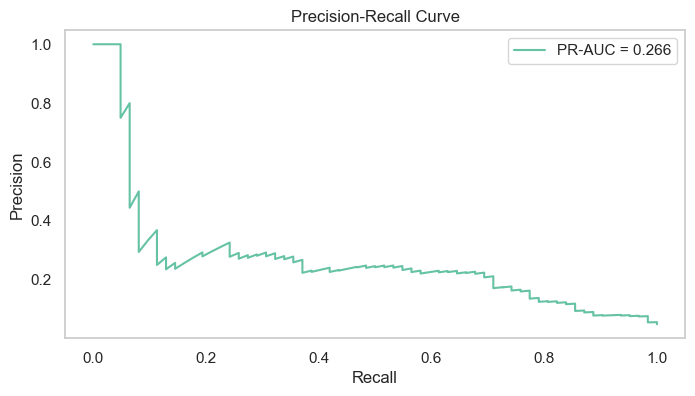

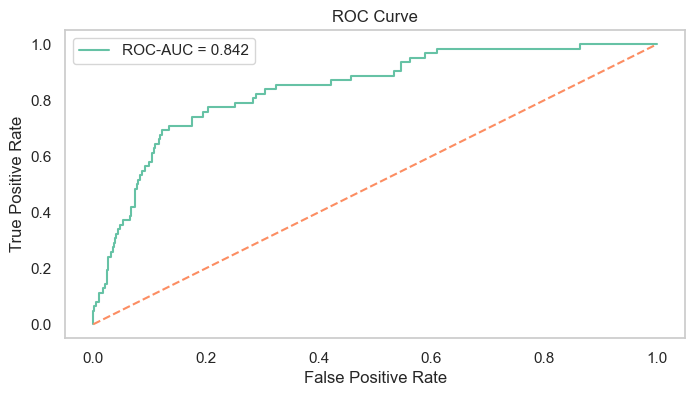

In [68]:
precision, recall, _ = precision_recall_curve(
    y_test,
    y_proba
)

pr_auc = average_precision_score(
    y_test,
    y_proba
)

plt.figure(figsize=(8, 4))

plt.plot(
    recall,
    precision,
    label=f'PR-AUC = {pr_auc:.3f}'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid()
plt.show()


fpr, tpr, _ = roc_curve(
    y_test,
    y_proba
)

roc_auc = roc_auc_score(
    y_test,
    y_proba
)

plt.figure(figsize=(8, 4))

plt.plot(
    fpr,
    tpr,
    label=f'ROC-AUC = {roc_auc:.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.show()

Модель показала ROC-AUC = 0.842, что свидетельствует о хорошей способности различать пациентов с инсультом и без него. При этом PR-AUC = 0.267 отражает более сложную ситуацию с точки зрения выявления редкого положительного класса: увеличение Recall сопровождается снижением Precision. Таким образом, основная проблема модели заключается не столько в способности ранжировать пациентов по риску, сколько в выборе подходящего порога классификации с учетом дисбаланса классов

<Figure size 700x600 with 0 Axes>

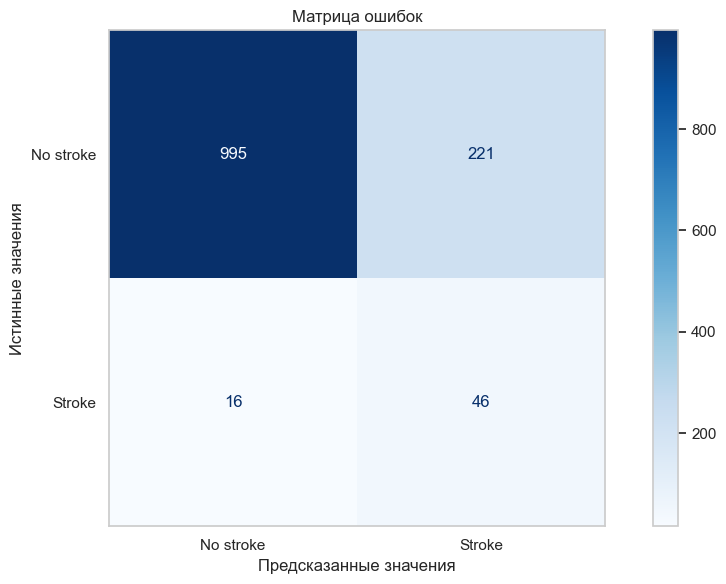

In [69]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No stroke', 'Stroke']
)

disp.plot(cmap='Blues')

plt.title('Матрица ошибок')
plt.xlabel('Предсказанные значения')
plt.ylabel('Истинные значения')
plt.grid()

plt.tight_layout()
plt.show()

При пороге `0.08` модель правильно определила 46 из 62 случаев инсульта, пропустив 16, при этом допустила 220 ложноположительных предсказаний. Таким образом, модель хорошо выявляет положительный класс, но ценой большого количества ложных тревог.

### Интерпретация модели

In [70]:
preprocessor_fitted = final_pipeline.named_steps['preprocessor']
model = final_pipeline.named_steps['model']

raw_feature_names = pd.Index(
    preprocessor_fitted.get_feature_names_out()
)

feature_names = (
    raw_feature_names
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})
feature_importance['odds_ratio'] = np.exp(
    feature_importance['coefficient']
)

feature_importance = feature_importance.sort_values(
    'coefficient',
    key=np.abs,
    ascending=False
)

feature_importance

,feature,coefficient,odds_ratio
0,age,1.633601,5.122289
11,work_type_children,0.322951,1.381198
10,work_type_Self-employed,-0.292902,0.746095
15,smoking_status_smokes,0.257281,1.293409
1,avg_glucose_level,0.233994,1.263636
14,smoking_status_never smoked,-0.201489,0.817513
3,hypertension,0.078267,1.081411
8,work_type_Never_worked,-0.067446,0.934778
4,heart_disease,0.058080,1.059800
12,smoking_status_Unknown,-0.044371,0.956599


### Интерпретация коэффициентов

В Logistic Regression коэффициенты линейно влияют на **log-odds** положительного класса.

С помощью экспоненты коэффициент переводится в **Odds Ratio**:

* `coefficient > 0` → признак увеличивает odds `stroke`;
* `coefficient < 0` → признак уменьшает odds `stroke`;
* `Odds Ratio > 1` → odds увеличиваются;
* `Odds Ratio < 1` → odds уменьшаются.

При этом итоговая вероятность `stroke` получается через логистическую функцию, поэтому зависимость признаков от вероятности является **нелинейной**.

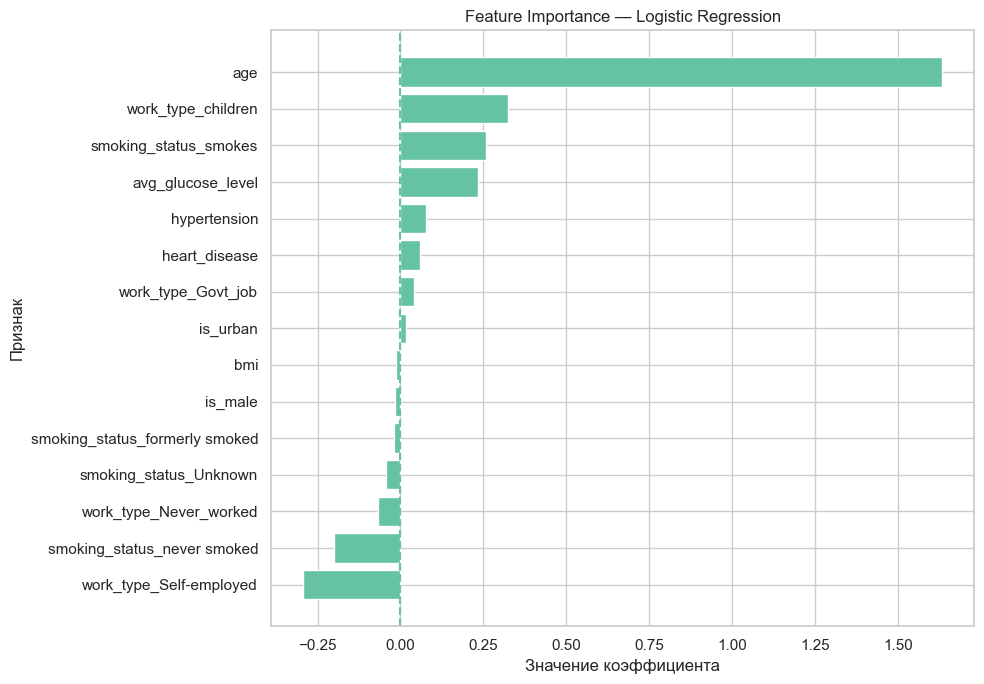

In [71]:
top_features = (
    feature_importance
    .head(15)
    .sort_values('coefficient')
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['feature'],
    top_features['coefficient']
)

plt.axvline(
    0,
    linestyle='--'
)

plt.xlabel('Значение коэффициента')
plt.ylabel('Признак')
plt.title('Feature Importance — Logistic Regression')

plt.tight_layout()
plt.show()

### Интерпретация Feature Importance

1. `age` — доминирующий предиктор
age имеет коэффициент ~1.6–1.7 — это на порядок больше всех остальных признаков. Это ожидаемо и клинически логично: риск инсульта резко растёт с возрастом

2. `smoking_status_smokes`
курение — один из значимых факторов риска инсульта в модели (коэффициент ≈ +0.25), что согласуется с медицинскими данными и логично дополняет паттерн: риск выше у курящих, ниже у некурящих (~−0.20), эффект у бросивших курить — нейтральный

3. `avg_glucose_level` и `hypertension`/`heart_disease` — работают в правильном направлении
Все три положительные, что согласуется с медицинской логикой (гипергликемия, гипертония и болезни сердца — известные факторы риска инсульта). Величина у hypertension и heart_disease довольно скромная (~0.05–0.08) — возможно, эффект частично "перетянут" на себя возрастом

4. `work_type_children` — подозрительный результат
нестабилен из-за экстремально малого числа положительных случаев в этой категории (2 из 916)

5. `work_type_Self-employed` — самый сильный отрицательный эффект
Наравне с `smoking_status_never smoked` (тоже отрицательный) это может отражать корреляцию с возрастом и образом жизни, а не прямую причинно-следственную связь. Возможно, самозанятые в выборке в среднем моложе/здоровее

6. `bmi` и `is_male` — почти нулевой вклад
Это тревожный звоночек: BMI обычно является значимым фактором риска. Здесь коэффициент близок к нулю — возможные причины:
- признаки не были стандартизированы (в отличие от, скажем, glucose_level), из-за чего коэффициент BMI выглядит "сжатым" на графике, х- отя по шкале признака эффект может быть весомым;
- либо BMI действительно теряет предсказательную силу на фоне age в данной модели

7. `is_urban`, `work_type_Private`, `smoking_status_formerly smoked`
эффект практически отсутствует, доверять их знаку не стоит без проверки статистической значимости (p-value/CI)

## Итоговая оценка модели

### Что получилось хорошо

- **`age` — сильный и клинически обоснованный предиктор.** Доминирует над остальными признаками, что полностью соответствует медицинской логике: риск инсульта растёт с возрастом.
- **`avg_glucose_level`, `hypertension`, `heart_disease`** — все работают в правильном направлении (положительный вклад в риск), согласуются с известными факторами риска инсульта.
- **`smoking_status_*`** — логичный и согласованный паттерн: `smokes`/`formerly smoked` повышают риск, `never smoked` — снижает. Хороший пример "здорового" сигнала, где направление и порядок величин совпадают с ожиданиями.
- **Recall-ориентированный подбор порога** — для медицинской задачи выбран порог с приоритетом на Recall, что снижает риск пропуска реального случая инсульта (цена False Negative выше цены False Positive).

### Что стоит улучшить / ограничения

- **`work_type_children` — второй по значимости признак, но ненадёжен.** Категория опирается всего на 916 наблюдений, из которых лишь 2 положительных случая (stroke=1) — статистически крайне малая база для устойчивой оценки. Признак фактически дублирует информацию о возрасте (age < 18) и создаёт риск квазиразделения (complete separation) в логреге. Решение — либо исключить признак из модели, либо явно пометить его как нестабильный и не делать на нём содержательных выводов.
- **`bmi` — слабый вклад.** Направление коэффициента правильное (положительное), но величина близка к нулю — сопоставима с `is_male`. Требует проверки на мультиколлинеарность с `age`/`avg_glucose_level`, либо признания, что признак слабо информативен в текущей линейной постановке.
- **Низкий PR-AUC (0.266) и низкий Precision на выбранном пороге.** Ожидаемо при сильном дисбалансе классов (~5% stroke=1), но означает много ложноположительных срабатываний — практическая применимость модели как есть ограничена без дополнительной калибровки или более сложных методов.
- **Линейность модели не улавливает нелинейные зависимости** — например, для BMI и возраста риск часто имеет немонотонный характер (U-образная зависимость), которую логрег принципиально не может отразить.
- **Не проверена статистическая значимость коэффициентов** (p-value/доверительные интервалы) — часть признаков с малыми коэффициентами (`is_urban`, `work_type_Private`, `is_male`) могут быть попросту незначимы, но это не проверено формально.
- **Дисбаланс классов учтён только через `class_weight`** — стоит также сравнить с альтернативными подходами (SMOTE, undersampling) или более гибкими моделями (Random Forest, Gradient Boosting), которые могут лучше справиться с нелинейностью и редким классом.

### Итог
Модель хорошо интерпретируема и в целом медицински логична по основным признакам (age, glucose, hypertension, smoking), что хороший результат для первого проекта. Главные точки роста — разобраться с `work_type_children` (нестабильный вес), учитывать это ограничение в выводах, и при желании сравнить с нелинейными моделями для более высокого Precision/PR-AUC.

## Итоги проекта

### 1. Что показал EDA

В датасете **5 110 строк и 12 признаков**, дубликатов не нашлось, пропуски были только в `bmi` (~4%) — закрыл их медианой по возрастным группам.
Главная особенность данных: инсульт есть лишь у **4.87%** пациентов, поэтому Accuracy тут почти ничего не говорит, и всю оценку я строил на **PR-AUC**.
Сильнее всего на целевую влияет возраст: до 35 лет случаев практически нет, ещё заметно играют гипертония, болезни сердца и курение.
Признак `ever_married` я убрал — связь с инсультом была, но она целиком объяснялась возрастом (женатые просто старше).
Выбросы в `bmi` и глюкозе удалять не стал: это реальные клинические значения, а не ошибки измерения.

### 2. Какая модель оказалась лучшей

Победила обычная **Logistic Regression** — сам удивился, честно рассчитывал, что бустинги порвут её.
По PR-AUC на тесте она дала **0.267** против 0.179–0.210 у CatBoost/LightGBM, и 10-fold CV это подтвердила (**0.224** — снова лучшая), так что это не везение удачного сплита.
Гиперпараметры подобрал Optuna, из них реально повлиял только `C`.
Decision Tree отвалилась сразу (PR-AUC 0.052) — исключил её из сравнения.
Приятный бонус логрегра: коэффициенты читаются руками, и можно объяснить, почему модель выдала именно такой риск.

| Модель | PR-AUC (test) | PR-AUC (CV) |
|---|---|---|
| **Logistic Regression** | **0.267** | **0.224** |
| Бустинги (CatBoost / LightGBM) | 0.179–0.210 | — |
| Decision Tree | 0.052 | — |

### 3. Какие метрики получились

С порогом по умолчанию (0.5) модель была бесполезна: **Recall = 0.016**, то есть инсульт она по сути никогда и не предсказывала.
Поэтому я сдвинул порог на **0.08** — Recall прыгнул до **0.742**: из 62 реальных случаев поймано 46, пропущено 16.
Обратная сторона — Precision всего **0.172**, ложных срабатываний примерно в шесть раз больше, чем попаданий.
При этом **ROC-AUC = 0.842**, а **PR-AUC = 0.266** — для базового уровня 0.049 это отрыв примерно в 5 раз.

| Порог | Precision | Recall |
|---|---|---|
| 0.50 | — | 0.016 |
| **0.08** | **0.172** | **0.742** |

> **Вывод.** Модель годится, чтобы выделять группу риска и отправлять человека на дообследование, но ставить диагноз по ней нельзя — слишком много ложных срабатываний.